In [1]:
import keras
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import expit

from fftdeep.data.arrays import get_arrays
from fftdeep.paths import PROJECT_ROOT
from fftdeep.visualization.gradcam import drop_test, grad_cam, load_logit_model

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
path = PROJECT_ROOT / "models" / "cnn_deeper_lrdecay.keras"

Xte, yte = get_arrays("test")
Xte = Xte.astype("float32")

model = keras.models.load_model(path, compile=False)
logit_model = load_logit_model(path)

x = Xte[:64]
p = model.predict(x, verbose=0).ravel()
z = logit_model.predict(x, verbose=0).ravel()
print("max difference:", np.abs(expit(z) - p).max())     

max difference: 5.9604645e-08


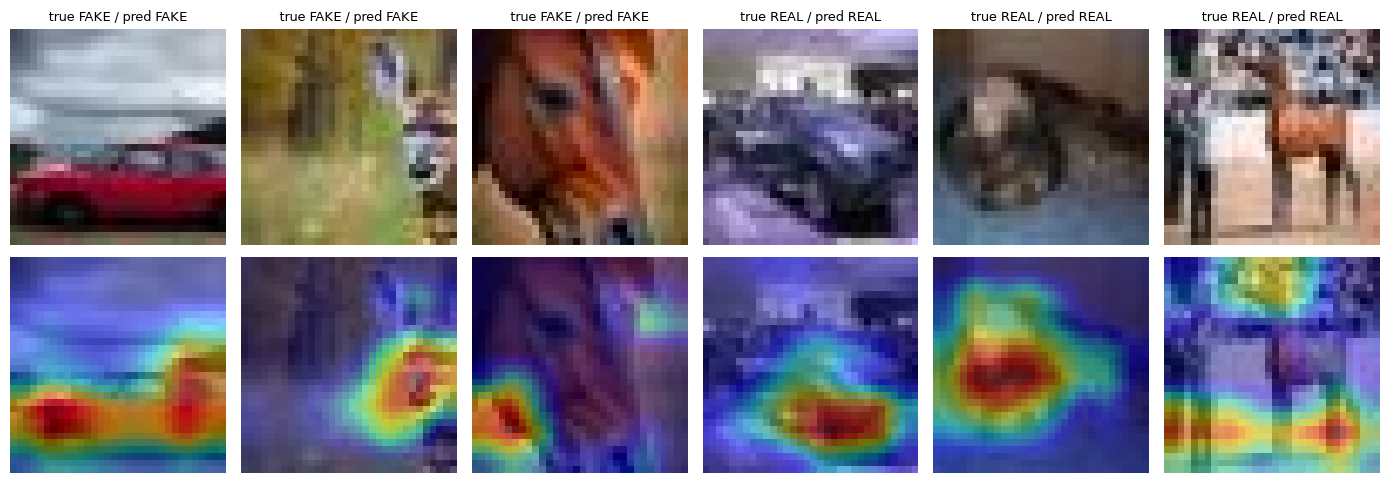

In [2]:
idx = np.random.default_rng(1).choice(len(Xte), 6, replace=False)
cams, logits = grad_cam(logit_model, Xte[idx])

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for j, i in enumerate(idx):
    pred = "FAKE" if logits[j] > 0 else "REAL"
    true = "FAKE" if yte[i] == 1 else "REAL"
    axes[0, j].imshow(Xte[i].astype("uint8"))
    axes[0, j].set_title(f"true {true} / pred {pred}", fontsize=9)
    axes[1, j].imshow(Xte[i].astype("uint8"))
    axes[1, j].imshow(cams[j], cmap="jet", alpha=0.45)
    axes[0, j].axis("off")
    axes[1, j].axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "gradcam_samples.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
idx = np.random.default_rng(2).choice(len(Xte), 500, replace=False)
cams, _ = grad_cam(logit_model, Xte[idx])
print(drop_test(logit_model, Xte[idx], cams))

(4.241359250962734, 6.575935120463371)
